# 🧮 LLM Quantization — A Practical, Hands-On Reference

**Goal:** one notebook that teaches *every widely-used LLM quantization technique*, runs each one on a real Hugging Face model, and measures the trade-off between **size**, **quality (perplexity)** and **speed** against the original FP16 model.

Everything runs on a **free Colab T4 GPU** (15 GB). The default model is small (`Qwen2.5-1.5B-Instruct`, ~3 GB in FP16), so no method needs more than a few GB.

## Table of contents

| # | Section | What you learn |
|---|---------|----------------|
| 0 | Setup & evaluation harness | Metrics: size, perplexity, tokens/s, peak GPU memory |
| 1 | Baseline (FP16) | The reference everything is compared to |
| 2 | Theory | Number formats, scale / zero-point, granularity, PTQ vs QAT |
| 3 | Quantization from scratch | absmax, asymmetric, group-wise, int4 packing, RTN on a whole LLM |
| 4 | bitsandbytes | LLM.int8(), NF4, FP4, double quantization |
| 5 | GPTQ | Hessian-based, calibration-driven weight quantization |
| 6 | AWQ | Activation-aware weight quantization |
| 7 | GGUF / llama.cpp | K-quants (Q2_K … Q8_0) for CPU/GPU inference |
| 8 | HQQ | Calibration-free quantization (fast, down to 2-bit) |
| 9 | Quanto & TorchAO | Library-native quantization (int8 / int4 / int2) |
| 10 | SmoothQuant (W8A8) | Why activations are hard, and the smoothing trick |
| 11 | KV-cache quantization | Cutting memory at long context |
| 12 | QLoRA | Fine-tuning on top of a 4-bit model |
| 13 | QAT | Quantization-aware training with the straight-through estimator |
| 14 | Other methods (overview) | AQLM, QuIP#, SpQR, FP8, BitNet, Marlin, vLLM |
| 15 | Final comparison | Tables, charts, and a decision guide |

## How to use

1. `Runtime → Change runtime type → T4 GPU`.
2. Run the cells top to bottom. Every method section is **independent**: if one fails (library/version issue), the notebook prints a warning and you can continue.
3. Results are saved to `quant_results.json` after every experiment, so a runtime restart will not lose them.
4. To use another model, change `MODEL_ID` in the config cell (suggestions are listed there).

> ⚠️ Colab's pre-installed packages change over time. If a section breaks, the first fix is usually `pip install -U <library>` followed by *Runtime → Restart session*.

## 0. Setup & evaluation harness

In [1]:
# pandas / matplotlib are pre-installed on Colab; upgrading pandas to 3.x conflicts with Colab's own packages.
!pip install -q -U transformers accelerate bitsandbytes optimum datasets sentencepiece huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.9/160.9 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
import os, gc, time, math, json, warnings, traceback
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
import transformers

transformers.logging.set_verbosity_error()
warnings.filterwarnings("ignore")
assert torch.cuda.is_available(), "No GPU! Runtime > Change runtime type > T4 GPU"
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0),
      f"| {torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB")

# ----------------------------- CONFIG ---------------------------------------
# Default: small, ungated, has official pre-quantized GPTQ / AWQ / GGUF repos.
# Other options (change MODEL_ID):
#   "Qwen/Qwen2.5-0.5B-Instruct"  -> fastest, great for quick tests
#   "Qwen/Qwen2.5-3B-Instruct"    -> fits T4, slower
#   "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
#   "microsoft/Phi-3.5-mini-instruct" (3.8B)
# Pre-quantized repo names below are derived from Qwen2.5 naming; for other
# families use the "quantize it yourself" cells instead.
MODEL_ID    = "Qwen/Qwen2.5-1.5B-Instruct"
PPL_CTX     = 512      # tokens per perplexity window
PPL_CHUNKS  = 40       # windows evaluated (~20k tokens). Raise for tighter estimates
GEN_TOKENS  = 128      # tokens generated for the speed test
RESULTS_PATH = "quant_results.json"
# -----------------------------------------------------------------------------

BASE_NAME = MODEL_ID.split("/")[-1].lower()          # e.g. qwen2.5-1.5b-instruct
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else []
print(f"{len(RESULTS)} saved results loaded")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
test = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
test_ids = tokenizer("\n\n".join(test["text"]), return_tensors="pt").input_ids
print("Perplexity corpus tokens:", test_ids.shape[1])

torch 2.11.0+cu130 | Tesla T4 | 14.6 GB
0 saved results loaded


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Perplexity corpus tokens: 299078


### Metrics

| Metric | How it is measured | Why it matters |
|---|---|---|
| **Size (MB)** | `model.get_memory_footprint()` (or file size for GGUF) | Can it fit on my device? |
| **Perplexity** | Wikitext-2 test set, non-overlapping 512-token windows. Lower = better. | Cheap proxy for quality loss |
| **Tokens/s** | Greedy generation of 128 tokens, batch size 1, after warm-up | Real decoding speed |
| **Peak GPU MB** | `torch.cuda.max_memory_allocated()` during generation | Real VRAM needed |

Perplexity is a proxy, not the whole story: a +2% perplexity can hide worse reasoning or instruction-following. Always eyeball some generations too (the harness saves one sample per model).

In [3]:
def free_memory():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

@torch.no_grad()
def perplexity(model, ids=test_ids, ctx=PPL_CTX, n_chunks=PPL_CHUNKS):
    model.eval()
    nll, count = 0.0, 0
    total = min(n_chunks, ids.size(1) // ctx)
    for i in range(total):
        x = ids[:, i * ctx:(i + 1) * ctx].to(model.device)
        loss = model(x, labels=x).loss.float().item()   # mean over ctx-1 predictions
        nll += loss * (ctx - 1)
        count += ctx - 1
    return math.exp(nll / count)

PROMPT = "Explain what quantization of neural networks is, in three short sentences."

@torch.no_grad()
def generation_speed(model, tok, prompt=PROMPT, new_tokens=GEN_TOKENS):
    text = tok.apply_chat_template([{"role": "user", "content": prompt}],
                                   tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to(model.device)
    kw = dict(do_sample=False, pad_token_id=tok.eos_token_id)
    model.generate(**inputs, max_new_tokens=8, **kw)                 # warm-up
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    out = model.generate(**inputs, max_new_tokens=new_tokens, min_new_tokens=new_tokens, **kw)
    torch.cuda.synchronize(); dt = time.perf_counter() - t0
    n_new = out.shape[1] - inputs.input_ids.shape[1]
    answer = tok.decode(out[0, inputs.input_ids.shape[1]:], skip_special_tokens=True)
    return n_new / dt, torch.cuda.max_memory_allocated() / 2**20, answer

def save_row(row):
    global RESULTS
    RESULTS = [r for r in RESULTS if r["name"] != row["name"]] + [row]
    json.dump(RESULTS, open(RESULTS_PATH, "w"), indent=1)
    show = {k: v for k, v in row.items() if k != "sample"}
    display(pd.DataFrame([show]))
    if row.get("sample"):
        print("Sample:", row["sample"][:350].replace("\n", " "), "...")

def evaluate(model, tok, name, family, bits, size_mb=None, speed=True):
    size = size_mb if size_mb is not None else model.get_memory_footprint() / 2**20
    ppl = perplexity(model)
    if speed:
        tps, peak, ans = generation_speed(model, tok)
    else:
        tps, peak, ans = float("nan"), float("nan"), ""
    save_row(dict(name=name, family=family, bits=bits, size_mb=round(size, 1),
                  perplexity=round(ppl, 3), tokens_per_s=round(tps, 1),
                  peak_gpu_mb=round(peak, 0), sample=ans))

def run(name, family, bits, model_id=MODEL_ID, **load_kwargs):
    """Load a (possibly quantized) model, evaluate it, free memory. Never crashes the notebook."""
    free_memory()
    try:
        t0 = time.time()
        model = AutoModelForCausalLM.from_pretrained(model_id, device_map="cuda", **load_kwargs)
        print(f"[{name}] loaded in {time.time() - t0:.0f}s")
        tok = AutoTokenizer.from_pretrained(model_id)
        evaluate(model, tok, name, family, bits)
        return True
    except Exception as e:
        print(f"⚠️  [{name}] failed: {type(e).__name__}: {str(e)[:300]}")
        return False
    finally:
        for v in ("model",):
            if v in locals():
                del model
        free_memory()

## 1. Baseline — FP16

Every number below is compared against this. (T4 has no native BF16, so we use FP16.)

In [4]:
run("FP16 baseline", "baseline", 16, torch_dtype=torch.float16)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[FP16 baseline] loaded in 73s


,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,FP16 baseline,baseline,16,2944.4,11.931,5.9,2963.0


Sample: Quantization of neural networks involves reducing the precision of weights and activations to lower bit representations (e.g., from 32-bit floating-point to 8-bit integers), which can significantly reduce memory usage and inference time while maintaining or even improving accuracy compared to full-precision models. This technique is particularly us ...


True

## 2. Theory in 10 minutes

### 2.1 Why quantize?

LLM inference is mostly **memory-bandwidth bound**: for each generated token the GPU must read *all* weights from memory. Fewer bytes per weight means (1) the model fits on smaller hardware and (2) tokens are generated faster.

$$\text{memory (GB)} \approx \frac{\text{parameters} \times \text{bits per weight}}{8 \times 10^9}$$

| Model | FP16 | INT8 | 4-bit | 2-bit |
|---|---|---|---|---|
| 1.5B | 3 GB | 1.5 GB | 0.75 GB | 0.4 GB |
| 7B | 14 GB | 7 GB | 3.5 GB | 1.75 GB |
| 70B | 140 GB | 70 GB | 35 GB | 17.5 GB |

(Real files are slightly larger: scales/zero-points, embeddings and some layers are kept in higher precision.)

### 2.2 Number formats

| Format | Bits | Layout (sign / exponent / mantissa) | Notes |
|---|---|---|---|
| FP32 | 32 | 1 / 8 / 23 | Training default in the past |
| FP16 | 16 | 1 / 5 / 10 | Small range (max ≈ 65 504), may overflow |
| BF16 | 16 | 1 / 8 / 7 | Same range as FP32, less precision. Needs Ampere+ |
| FP8 (E4M3 / E5M2) | 8 | 1 / 4 / 3  or  1 / 5 / 2 | Needs Hopper / Ada GPUs |
| INT8 | 8 | integer −128…127 | Uniform grid, needs a scale |
| INT4 | 4 | integer −8…7 | Uniform grid, needs a scale (per group) |
| NF4 | 4 | 16 non-uniform levels | Levels placed at quantiles of a normal distribution (QLoRA) |
| FP4 | 4 | 1 / 2 / 1 | Tiny float |

### 2.3 Affine quantization

Map a float tensor `x` to integers `q` with a **scale** `s` and (optionally) a **zero-point** `z`:

$$q = \text{clamp}\big(\text{round}(x / s) + z,\; q_{min},\; q_{max}\big), \qquad \hat{x} = s\,(q - z)$$

* **Symmetric (absmax):** `z = 0`, `s = max|x| / q_max`. Simple, fast, wastes range if the data is skewed.
* **Asymmetric (min-max):** `s = (max − min) / (2^b − 1)`, `z = round(−min / s)`. Uses the full integer range.

### 2.4 Granularity — *where* the scale is shared

| Granularity | One scale per… | Accuracy | Overhead |
|---|---|---|---|
| Per-tensor | whole weight matrix | worst (one outlier ruins everything) | minimal |
| Per-channel | output row | good for 8-bit | small |
| **Group-wise** | block of 32–128 weights in a row | best for 4-bit and below | ~0.25–0.5 extra bits/weight |

### 2.5 Taxonomy

* **PTQ (post-training quantization):** quantize an already-trained model. Cheap. Everything in this notebook except §12–13.
  * *Calibration-free:* round-to-nearest, bitsandbytes, HQQ, GGUF (basic), Quanto.
  * *Calibration-based:* GPTQ, AWQ, SmoothQuant, GGUF with imatrix. They run a few hundred sample texts through the model to find which weights/activations matter.
* **QAT (quantization-aware training):** simulate quantization *during* training so the model learns to be robust to it (§13).
* **Weight-only (W4A16, W8A16):** weights stored low-bit, dequantized on the fly, activations stay FP16. Best for latency-bound single-user inference.
* **Weight + activation (W8A8, FP8):** both low-bit so matmuls run in INT8/FP8 tensor cores. Best for high-throughput serving; activations have outliers, which makes this harder (§10).

### 2.6 Method map

| Method | Type | Bits | Calibration | Typical use |
|---|---|---|---|---|
| LLM.int8() (bnb) | W8A8 w/ outlier fp16 path | 8 | no | Easy memory saving, slow-ish |
| NF4 / FP4 (bnb) | weight-only | 4 | no | QLoRA fine-tuning |
| GPTQ | weight-only | 2–8 | yes | GPU inference, mature kernels |
| AWQ | weight-only | 4 | yes | GPU inference, fast and accurate |
| GGUF K-quants | weight-only | 2–8 | optional | CPU / Apple Silicon / mixed offload |
| HQQ | weight-only | 1–8 | no | Fast quantization, extreme low-bit |
| Quanto / TorchAO | weight-only (+act) | 2–8 | no | PyTorch-native pipelines |
| SmoothQuant | W8A8 | 8 | yes | Throughput serving |
| FP8 | W8A8 | 8 | light | H100 / L40 serving |

## 3. Quantization from scratch

Before using libraries, let's implement the core ideas in ~30 lines of PyTorch.

In [5]:
def quant_absmax(w, bits=8, group_size=None, per_channel=False):
    """Symmetric quantization. Returns (int tensor, scales, dequantized tensor)."""
    qmax = 2 ** (bits - 1) - 1
    shape = w.shape
    if group_size:
        wg = w.reshape(-1, group_size)
    elif per_channel:
        wg = w.reshape(shape[0], -1)
    else:
        wg = w.reshape(1, -1)
    scale = wg.abs().amax(dim=1, keepdim=True).clamp(min=1e-8) / qmax
    q = torch.round(wg / scale).clamp(-qmax - 1, qmax)
    return q.to(torch.int8).reshape(shape), scale, (q * scale).reshape(shape)

def quant_asym(w, bits=8, group_size=None):
    """Asymmetric (min-max) quantization with zero-point."""
    qmax = 2 ** bits - 1
    wg = w.reshape(-1, group_size) if group_size else w.reshape(1, -1)
    wmin, wmax = wg.amin(1, keepdim=True), wg.amax(1, keepdim=True)
    scale = ((wmax - wmin) / qmax).clamp(min=1e-8)
    zp = torch.round(-wmin / scale)
    q = torch.clamp(torch.round(wg / scale) + zp, 0, qmax)
    return q.to(torch.uint8).reshape(w.shape), scale, zp, ((q - zp) * scale).reshape(w.shape)

# Toy example
x = torch.tensor([[-1.2, 0.05, 0.8, 2.4, -0.3, 0.0, 1.1, -2.0]])
q, s, x_hat = quant_absmax(x, bits=4)
print("original :", x.numpy().round(3))
print("int4     :", q.numpy())
print("scale    :", s.item())
print("restored :", x_hat.numpy().round(3))
print("abs error:", (x - x_hat).abs().numpy().round(3))

original : [[-1.2   0.05  0.8   2.4  -0.3   0.    1.1  -2.  ]]
int4     : [[-4  0  2  7 -1  0  3 -6]]
scale    : 0.34285715222358704
restored : [[-1.371  0.     0.686  2.4   -0.343  0.     1.029 -2.057]]
abs error: [[0.171 0.05  0.114 0.    0.043 0.    0.071 0.057]]


### 3.1 Real weights: how much does granularity matter?

We take a real MLP weight from the model and measure the reconstruction error for different bit-widths and granularities. Then we add an artificial **outlier** column (real LLMs have these!) to see why per-tensor scaling breaks.

In [6]:
cpu_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16)
W = cpu_model.model.layers[10].mlp.down_proj.weight.data.float().clone()
del cpu_model; gc.collect()
print("weight shape:", tuple(W.shape), "| std:", W.std().item(), "| max|w|:", W.abs().max().item())

def mse(w, w_hat): return ((w - w_hat) ** 2).mean().item()

def sweep(W):
    rows = []
    for bits in [8, 6, 4, 3, 2]:
        rows.append(dict(bits=bits,
            per_tensor=mse(W, quant_absmax(W, bits)[2]),
            per_channel=mse(W, quant_absmax(W, bits, per_channel=True)[2]),
            group_128=mse(W, quant_absmax(W, bits, group_size=128)[2]),
            group_32=mse(W, quant_absmax(W, bits, group_size=32)[2]),
            asym_group_128=mse(W, quant_asym(W, bits, group_size=128)[3])))
    return pd.DataFrame(rows).set_index("bits")

print("MSE on the real weight:")
display(sweep(W).style.format("{:.2e}"))

W_out = W.clone(); W_out[:, 5] *= 40          # one outlier input channel
print("MSE with an artificial outlier column:")
display(sweep(W_out).style.format("{:.2e}"))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

weight shape: (1536, 8960) | std: 0.026986118406057358 | max|w|: 0.828125
MSE on the real weight:


,per_tensor,per_channel,group_128,group_32,asym_group_128
bits,,,,,
8,3.54e-06,1.05e-07,3.70e-08,2.33e-08,2.93e-08
6,5.94e-05,1.76e-06,6.20e-07,3.91e-07,4.80e-07
4,6.26e-04,3.42e-05,1.22e-05,7.67e-06,8.47e-06
3,7.22e-04,1.71e-04,6.57e-05,4.17e-05,3.88e-05
2,7.28e-04,6.61e-04,4.48e-04,3.23e-04,2.05e-04


MSE with an artificial outlier column:


,per_tensor,per_channel,group_128,group_32,asym_group_128
bits,,,,,
8,1.38e-04,6.18e-06,1.24e-07,4.48e-08,5.32e-08
6,7.04e-04,8.81e-05,1.86e-06,7.00e-07,8.61e-07
4,7.32e-04,4.41e-04,1.81e-05,9.17e-06,1.21e-05
3,7.57e-04,6.06e-04,7.30e-05,4.36e-05,4.52e-05
2,8.39e-04,7.19e-04,4.51e-04,3.24e-04,2.11e-04


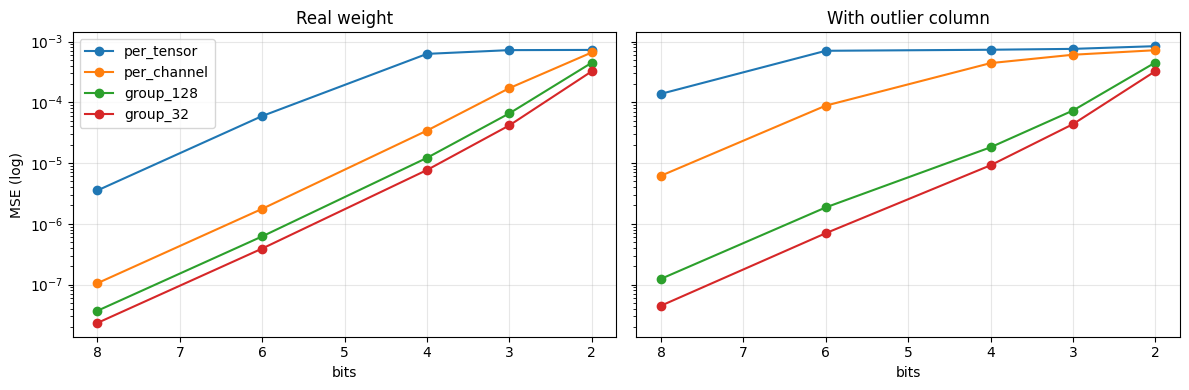

In [7]:
df_a, df_b = sweep(W), sweep(W_out)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, d, t in zip(ax, [df_a, df_b], ["Real weight", "With outlier column"]):
    for c in ["per_tensor", "per_channel", "group_128", "group_32"]:
        a.plot(d.index, d[c], marker="o", label=c)
    a.set_yscale("log"); a.invert_xaxis(); a.set_xlabel("bits"); a.set_title(t); a.grid(alpha=.3)
ax[0].set_ylabel("MSE (log)"); ax[0].legend(); plt.tight_layout(); plt.show()

**Takeaways:** error roughly quadruples per bit removed; per-tensor scaling collapses with outliers; small groups are the cheapest way to keep 4-bit accurate. This is why almost every 4-bit method uses **group size 32–128**.

### 3.2 Packing: how int4 really lives in memory

PyTorch has no 4-bit dtype, so two 4-bit values are packed into one byte.

In [8]:
q4 = torch.randint(-8, 8, (8,), dtype=torch.int8)
u = (q4 + 8).to(torch.uint8)                       # shift to 0..15
packed = u[0::2] | (u[1::2] << 4)                  # 2 values / byte
unpacked = torch.stack([packed & 0xF, packed >> 4], 1).flatten().to(torch.int8) - 8
print("int4 values :", q4.tolist())
print("packed bytes:", packed.tolist(), f"({q4.numel()} values -> {packed.numel()} bytes)")
print("round trip OK:", torch.equal(q4, unpacked))

int4 values : [3, 6, 4, -7, 3, -5, -3, -4]
packed bytes: [235, 28, 59, 69] (8 values -> 4 bytes)
round trip OK: True


### 3.3 Round-to-nearest (RTN) on the whole LLM

We apply `quant_absmax` to **every** Linear layer (except `lm_head`) and measure perplexity. This is "fake" (simulated) quantization: weights are quantized and immediately dequantized, so the model stays FP16 in memory. The reported size is the *theoretical* packed size, and speed is not measured. It is the simplest possible PTQ and the baseline that GPTQ/AWQ improve on.

In [9]:
@torch.no_grad()
def rtn_quantize_model(model, bits=4, group_size=128, per_channel=False, skip=("lm_head",)):
    for n, m in model.named_modules():
        if isinstance(m, nn.Linear) and not any(s in n for s in skip):
            _, _, w_hat = quant_absmax(m.weight.data.float(), bits, group_size, per_channel)
            m.weight.data = w_hat.to(m.weight.dtype)

def theoretical_size_mb(model, bits, group_size=None, skip=("lm_head",)):
    lin = sum(m.weight.numel() for n, m in model.named_modules()
              if isinstance(m, nn.Linear) and not any(s in n for s in skip))
    other = sum(p.numel() for p in model.parameters()) - lin
    scales = (lin / group_size) * 2 if group_size else 0
    return (lin * bits / 8 + scales + other * 2) / 2**20

rtn_configs = [
    ("RTN W8 per-channel (simulated)", 8, None, True),
    ("RTN W4 group-128 (simulated)",   4, 128,  False),
    ("RTN W4 per-channel (simulated)", 4, None, True),
    ("RTN W3 group-128 (simulated)",   3, 128,  False),
]
for name, bits, gs, pc in rtn_configs:
    free_memory()
    m = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="cuda")
    rtn_quantize_model(m, bits, gs, pc)
    evaluate(m, tokenizer, name, "RTN (simulated)", bits,
             size_mb=theoretical_size_mb(m, bits, gs), speed=False)
    del m; free_memory()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,RTN W8 per-channel (simulated),RTN (simulated),8,1694.9,11.977,NaN,NaN


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,RTN W4 group-128 (simulated),RTN (simulated),4,1089.7,14.592,NaN,NaN


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,RTN W4 per-channel (simulated),RTN (simulated),4,1070.2,21.923,NaN,NaN


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,RTN W3 group-128 (simulated),RTN (simulated),3,933.5,104.005,NaN,NaN


Notice how **W4 per-channel** degrades much more than **W4 group-128**, and W3 gets painful. The advanced methods below close this gap with smarter rounding (GPTQ), smarter scaling (AWQ) or better codebooks (NF4, K-quants, HQQ).

## 4. bitsandbytes — LLM.int8(), NF4, FP4

The most convenient route: add a config to `from_pretrained` and the model is quantized **on load**, with no calibration.

* **LLM.int8()** (Dettmers et al., 2022): INT8 matmul, but the few "outlier" feature dimensions (magnitude > 6) are computed in FP16 (mixed-precision decomposition). Near-lossless, but slower than FP16 on many GPUs.
* **NF4** (QLoRA, 2023): 4-bit data type whose 16 levels are the quantiles of a standard normal distribution, which is information-theoretically good for bell-shaped weights. Block size 64.
* **FP4:** plain 4-bit float, usually a bit worse than NF4.
* **Double quantization:** the per-block scales are themselves quantized to 8-bit, saving ~0.37 bits/weight.
* **Compute dtype:** weights are stored 4-bit, but dequantized to this dtype for the matmul.

In [10]:
run("bnb INT8 (LLM.int8)", "bitsandbytes", 8,
    torch_dtype=torch.float16,
    quantization_config=BitsAndBytesConfig(load_in_8bit=True))

run("bnb NF4 + double quant", "bitsandbytes", 4, torch_dtype=torch.float16,
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16))

run("bnb NF4 (no double quant)", "bitsandbytes", 4, torch_dtype=torch.float16,
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=False, bnb_4bit_compute_dtype=torch.float16))

run("bnb FP4", "bitsandbytes", 4, torch_dtype=torch.float16,
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="fp4",
        bnb_4bit_compute_dtype=torch.float16))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[bnb INT8 (LLM.int8)] loaded in 23s


,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,bnb INT8 (LLM.int8),bitsandbytes,8,1694.9,12.015,3.1,1724.0


Sample: Quantization of neural networks involves reducing the precision of weights and activations to lower bit representations (e.g., from 32-bit floating-point numbers to 8-bit integers), which can significantly reduce memory usage and inference time while maintaining or even improving accuracy compared to full-precision models. This technique is particu ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[bnb FP4] loaded in 7s


,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,bnb FP4,bitsandbytes,4,1070.2,14.455,8.2,1176.0


Sample: Quantization of neural networks reduces the precision of activations and weights to fewer bits, enabling faster inference speeds but potentially sacrificing some accuracy for real-time applications. It involves mapping values from higher-precision formats like FP32 (single precision) to lower-precision formats like INT8 or UINT8 (fixed-point). This ...


True

**When to use bitsandbytes:** quick experiments, QLoRA fine-tuning (§12), and when you can't spend time on calibration. For production serving, GPTQ/AWQ kernels are usually faster.

## 5. GPTQ

**Idea (Frantar et al., 2022):** quantize one layer at a time, and *compensate* rounding error. For a layer `Y = XW`, GPTQ minimizes `‖XW − XŴ‖²` using the Hessian `H = 2XᵀX` computed from calibration data. It quantizes weights column by column; after rounding each column, the remaining un-quantized columns are updated to absorb the error (an efficient variant of Optimal Brain Surgeon).

Key knobs:

| Parameter | Meaning |
|---|---|
| `bits` | 2, 3, 4, 8 |
| `group_size` | 128 is the usual sweet spot (−1 = per-channel) |
| `desc_act` | quantize columns by decreasing activation magnitude (better accuracy, slower kernels) |
| `sym` | symmetric or asymmetric grid |
| calibration set | ~128 samples × 512–2048 tokens |

Quantizing a 1.5B model takes ~10–20 min on a T4; a 7B model takes ~1 hour on an A100. So we first load **official pre-quantized checkpoints**, then show how to do it yourself.

In [11]:
!pip install -q gptqmodel --no-build-isolation

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 12.0 MB/s eta 0:00:00
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.0/215.0 kB 17.7 MB/s eta 0:00:00
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.6/115.6 kB 11.0 MB/s eta 0:00:00
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.4/65.4 kB 6.3 MB/s eta 0:00:00
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 91.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 23.0 MB/s eta 0:00:

In [12]:
from transformers import GPTQConfig

# gptqmodel's default (Marlin) kernel needs a CUDA JIT build that fails on Colab's T4 / CUDA 13.
# Choose a kernel explicitly instead: Triton first, pure-PyTorch as a last resort.
GPTQ_BACKENDS = ("gptq_triton", "gptq_torch")

for name, bits, repo in [("GPTQ INT4 (pre-quantized)", 4, f"{MODEL_ID}-GPTQ-Int4"),
                         ("GPTQ INT8 (pre-quantized)", 8, f"{MODEL_ID}-GPTQ-Int8")]:
    for backend in GPTQ_BACKENDS:
        ok = run(name, "GPTQ", bits, model_id=repo, torch_dtype=torch.float16,
                 quantization_config=GPTQConfig(bits=bits, backend=backend))
        if ok:
            break

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]


INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.5.0
Transformers : 5.19.0
Torch        : 2.11.0+cu130
Triton       : 3.6.0


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.15GB            

model.safetensors: downloading bytes:           |  0.00B            

INFO  Kernel: selected: `TritonV2Linear`                                        


...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,GPTQ INT8 (pre-quantized),GPTQ,8,1726.1,11.943,10.5,2865.0


Sample: Quantization of neural networks involves reducing the precision of weights and activations to lower bit representations (e.g., from 32-bit floating-point to 8-bit integers), which can significantly reduce memory usage and inference time while maintaining or even improving accuracy compared to full-precision models. This technique is particularly us ...


### Quantize it yourself with GPTQ (optional, ~15 min)

We build the calibration set from the Wikitext **train** split so it never overlaps with the test set we use for perplexity.

In [13]:
RUN_OWN_GPTQ = False        # set True to run

if RUN_OWN_GPTQ:
    from gptqmodel import GPTQModel, GPTQConfig as GPTQMConfig
    from transformers import GPTQConfig
    train = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
    calib = [t for t in train["text"] if len(t) > 500][:128]

    m = GPTQModel.load(MODEL_ID, GPTQMConfig(bits=4, group_size=128))
    m.quantize(calib, batch_size=1)
    m.save("my-gptq-4bit"); tokenizer.save_pretrained("my-gptq-4bit")
    del m; free_memory()
    for backend in ("gptq_triton", "gptq_torch"):
        if run("GPTQ INT4 (own, wikitext calib)", "GPTQ", 4, model_id="my-gptq-4bit", torch_dtype=torch.float16,
               quantization_config=GPTQConfig(bits=4, backend=backend)):
            break

## 6. AWQ — Activation-aware Weight Quantization

**Idea (Lin et al., 2023):** not all weights matter equally. About **1% of weight channels** are "salient", the ones multiplied by large activations. Instead of keeping them in FP16 (which makes kernels awkward), AWQ **scales those channels up before quantization** (and folds the inverse scale into the previous op), so their relative rounding error shrinks. The scales are found by a quick grid search on a small calibration set. No backprop, no Hessian, so it is fast and generalizes well across domains.

> ⚠️ `autoawq` can pin its own PyTorch version. If the next cell reinstalls torch, restart the session once and re-run the setup cells (your results are safe in `quant_results.json`). The AutoAWQ project is in maintenance mode; the AWQ algorithm lives on in `llm-compressor` and in vLLM, and AWQ checkpoints keep loading in Transformers.

In [14]:
!pip install -q autoawq

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 1.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [15]:
run("AWQ INT4 (pre-quantized)", "AWQ", 4,
    model_id=f"{MODEL_ID}-AWQ", torch_dtype=torch.float16)

config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.61GB            

model.safetensors: downloading bytes:           |  0.00B            

INFO  ExLlamaV2 AWQ: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/exllamav2_awq/28102340d90d94d7`.
INFO  ExLlamaV2 AWQ: torch.ops JIT extension ready in 114s (estimated ~35s, +79s).
INFO  Kernel: Auto-selection: adding candidate `AwqExllamaV2Linear`             
INFO  Kernel: selected -> `AwqExllamaV2Linear`.                                 


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

...

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,AWQ INT4 (pre-quantized),AWQ,4,1094.6,13.035,16.6,2306.0


Sample: Quantization of neural networks involves reducing the number of bits used to represent weights and activations within the network, which can significantly decrease computational requirements while maintaining performance. This process often uses techniques like fixed-point arithmetic or integer arithmetic to achieve lower precision but higher effic ...


True

### Quantize it yourself with AWQ (optional)

In [16]:
RUN_OWN_AWQ = False         # set True to run (needs ~10 min)

if RUN_OWN_AWQ:
    # AutoAWQ (`import awq`) is deprecated and no longer imports with current torch / transformers.
    # GPTQModel implements the same AWQ algorithm and writes checkpoints that load the same way.
    from gptqmodel import GPTQModel, AWQConfig
    train = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
    calib = [t for t in train["text"] if len(t) > 500][:128]

    m = GPTQModel.load(MODEL_ID, AWQConfig(bits=4, group_size=128))
    m.quantize(calib, batch_size=1)
    m.save("my-awq-4bit"); tokenizer.save_pretrained("my-awq-4bit")
    del m; free_memory()
    run("AWQ INT4 (own)", "AWQ", 4, model_id="my-awq-4bit", torch_dtype=torch.float16)

## 7. GGUF & llama.cpp K-quants

**GGUF** is the single-file format used by `llama.cpp`, Ollama, LM Studio, etc. It runs on CPU, Apple Silicon, and NVIDIA GPUs, with optional layer offloading. Its quantization types:

| Type | Bits/weight (≈) | Notes |
|---|---|---|
| `Q8_0` | 8.5 | Near-lossless |
| `Q6_K` | 6.6 | Very close to FP16 |
| `Q5_K_M` | 5.7 | Great quality/size |
| **`Q4_K_M`** | 4.8 | **The community default** |
| `Q3_K_M` | 3.9 | Noticeable loss |
| `Q2_K` | 3.4 | Heavy loss, only for tight memory |
| `IQ2_XS`, `IQ3_XXS`, … | 2–3 | "I-quants": use an importance matrix (imatrix) for better low-bit quality |

**K-quants:** weights are grouped into *super-blocks* of 256 values, split into sub-blocks (e.g. 16 or 32 values) that each get their own scale/min; the scales themselves are quantized. `_S/_M/_L` indicate how many sensitive tensors (like `attn_v`, `ffn_down`) get a higher-precision type.

We download the official Qwen GGUF files and evaluate each type. Perplexity is computed with the same token windows as before, using `llama-cpp-python` (so numbers are close to, but not bit-for-bit comparable with, the Transformers path).

In [17]:
# Prebuilt CUDA wheel (fast). If it fails, see the CPU / build-from-source alternatives below.
!pip install -q llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu124
# Alternative (builds from source, ~10 min):
# !CMAKE_ARGS="-DGGML_CUDA=on" pip install -q llama-cpp-python --no-cache-dir
# CPU only:  !pip install -q llama-cpp-python

# The cu124 wheel needs the CUDA-12 runtime libraries (libcudart.so.12 ...), but Colab now ships CUDA 13.
# Install them from PyPI and preload them so llama.cpp can find them.
!pip install -q nvidia-cuda-runtime-cu12 nvidia-cublas-cu12
import ctypes, glob, site

def _preload_cuda12():
    roots = set(site.getsitepackages() + [site.getusersitepackages()])
    for pat in ("nvidia/cuda_runtime/lib/libcudart.so.12*",
                "nvidia/cublas/lib/libcublasLt.so.12*",
                "nvidia/cublas/lib/libcublas.so.12*"):
        for root in roots:
            for p in glob.glob(f"{root}/{pat}"):
                try:
                    ctypes.CDLL(p, mode=ctypes.RTLD_GLOBAL)
                    break
                except OSError:
                    pass

_preload_cuda12()
try:
    import llama_cpp
    print("llama-cpp-python loaded (CUDA build)")
except Exception as e:
    print(f"⚠️  CUDA wheel could not load ({type(e).__name__}); installing the CPU wheel instead (same results, slower).")
    !pip install -q --no-deps --force-reinstall llama-cpp-python --index-url https://abetlen.github.io/llama-cpp-python/whl/cpu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 GB ? eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.4 MB/s eta 0:00:00
llama-cpp-python loaded (CUDA build)


In [18]:
from huggingface_hub import hf_hub_download

def gguf_eval(quant):
    from llama_cpp import Llama
    path = hf_hub_download(f"{MODEL_ID}-GGUF", f"{BASE_NAME}-{quant}.gguf")
    size_mb = os.path.getsize(path) / 2**20
    llm = Llama(model_path=path, n_ctx=PPL_CTX, n_gpu_layers=-1, logits_all=True, verbose=False)

    # perplexity on the same token windows as the HF models
    ids = test_ids[0].tolist()
    nll, count = 0.0, 0
    for i in range(min(PPL_CHUNKS, len(ids) // PPL_CTX)):
        chunk = ids[i * PPL_CTX:(i + 1) * PPL_CTX]
        llm.reset(); llm.eval(chunk)
        logits = torch.from_numpy(np.array(llm.scores[:PPL_CTX], dtype=np.float32))
        logp = logits[:-1].log_softmax(-1)
        tgt = torch.tensor(chunk[1:])
        nll += -logp.gather(1, tgt[:, None]).sum().item(); count += PPL_CTX - 1
    ppl = math.exp(nll / count)

    # speed
    llm.reset()
    prompt = tokenizer.apply_chat_template([{"role": "user", "content": PROMPT}],
                                           tokenize=False, add_generation_prompt=True)
    t0 = time.perf_counter()
    out = llm.create_completion(prompt, max_tokens=GEN_TOKENS, temperature=0.0)
    dt = time.perf_counter() - t0
    n = out["usage"]["completion_tokens"]
    bits = {"q2_k": 3.4, "q3_k_m": 3.9, "q4_k_m": 4.8, "q5_k_m": 5.7, "q6_k": 6.6, "q8_0": 8.5}.get(quant, 0)
    save_row(dict(name=f"GGUF {quant.upper()}", family="GGUF", bits=bits, size_mb=round(size_mb, 1),
                  perplexity=round(ppl, 3), tokens_per_s=round(n / dt, 1), peak_gpu_mb=float("nan"),
                  sample=out["choices"][0]["text"]))
    del llm; free_memory()

for q in ["q2_k", "q3_k_m", "q4_k_m", "q5_k_m", "q6_k", "q8_0"]:
    try:
        gguf_eval(q)
    except Exception as e:
        print(f"⚠️  GGUF {q} failed: {type(e).__name__}: {str(e)[:300]}")

qwen2.5-1.5b-instruct-q2_k.gguf: reconstructing file:   0%|          |  0.00B /  753MB            

qwen2.5-1.5b-instruct-q2_k.gguf: downloading bytes:           |  0.00B            

,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,GGUF Q2_K,GGUF,3.4,718.0,20.988,97.5,NaN


Sample: Quantization of neural networks refers to the process of converting a neural network's weights into a form that can be efficiently processed by a specific hardware, such as a GPU or FPGA. This involves mapping the weights to a smaller, more efficient representation that can be processed more quickly and less power-efficiently. This process is often ...


qwen2.5-1.5b-instruct-q3_k_m.gguf: reconstructing file:   0%|          |  0.00B /  924MB            

...

Sample: Quantization of neural networks is a technique that reduces the number of bits used to represent the weights and activations in a neural network, thereby decreasing the computational and memory requirements while maintaining or improving performance. ...


qwen2.5-1.5b-instruct-q8_0.gguf: reconstructing file:   0%|          |  0.00B / 1.89GB            

qwen2.5-1.5b-instruct-q8_0.gguf: downloading bytes:           |  0.00B            

,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,GGUF Q8_0,GGUF,8.5,1806.8,12.086,86.2,NaN


Sample: Quantization of neural networks is the process of reducing the precision of the weights and activations in a neural network to save memory and computation. It involves mapping the continuous values to a discrete set of values. ...


### Convert and quantize a model yourself with llama.cpp (optional)

This is the workflow for **any** HF model that has no GGUF yet. The `imatrix` step (optional) is what makes 2–3-bit I-quants usable.

In [19]:
RUN_LLAMACPP_BUILD = False   # set True to run (~8 min build)

if RUN_LLAMACPP_BUILD:
    !git clone -q --depth 1 https://github.com/ggml-org/llama.cpp
    !pip install -q -r llama.cpp/requirements/requirements-convert_hf_to_gguf.txt
    !cmake -S llama.cpp -B llama.cpp/build -DGGML_CUDA=ON -DLLAMA_CURL=OFF > /dev/null
    !cmake --build llama.cpp/build --config Release -j --target llama-quantize llama-imatrix llama-perplexity > /dev/null

    from huggingface_hub import snapshot_download
    local = snapshot_download(MODEL_ID, local_dir="hf_model")
    !python llama.cpp/convert_hf_to_gguf.py hf_model --outfile model-f16.gguf --outtype f16
    !llama.cpp/build/bin/llama-quantize model-f16.gguf model-q4_k_m.gguf Q4_K_M
    # With an importance matrix (needs a calibration text file):
    # !llama.cpp/build/bin/llama-imatrix -m model-f16.gguf -f calib.txt -o imatrix.dat -ngl 99
    # !llama.cpp/build/bin/llama-quantize --imatrix imatrix.dat model-f16.gguf model-iq3_xxs.gguf IQ3_XXS
    # Official perplexity tool:
    # !llama.cpp/build/bin/llama-perplexity -m model-q4_k_m.gguf -f wiki.test.raw -ngl 99

## 8. HQQ — Half-Quadratic Quantization

**Idea (Badri & Shaji, 2023):** no calibration data at all. HQQ treats quantization-parameter selection as an optimization problem with a sparsity-promoting loss (robust to outliers) and solves it in closed form with a half-quadratic splitting solver. Result: quantizing a big model takes **minutes**, and quality at 3–4 bit is competitive with calibrated methods. It also supports 2-bit and 1-bit.

In [20]:
# DISABLE_CUDA=1 skips building the optional ATEN CUDA kernels (the README documents this flag).
# We don't need them: the default PyTorch backend is what the notebook uses,
# and skipping the build avoids compile errors on Colab's Python 3.13.
!DISABLE_CUDA=1 pip install -q git+https://github.com/dropbox/hqq.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [21]:
import importlib, transformers.utils.import_utils as _iu

# transformers caches "is library X installed?" at import time. Clear those caches after a late pip install.
importlib.invalidate_caches()
for _n in dir(_iu):
    _f = getattr(_iu, _n)
    if _n.startswith("is_") and hasattr(_f, "cache_clear"):
        _f.cache_clear()

from transformers.utils import is_hqq_available
print("transformers sees HQQ:", is_hqq_available())

# transformers also imports HQQLinear once, at import time. If hqq was installed later, that import was skipped
# (-> "NameError: name 'HQQLinear' is not defined"), so reload the module now.
import transformers.quantizers.quantizer_hqq as _qh
importlib.reload(_qh)
print("HQQLinear available in transformers:", hasattr(_qh, "HQQLinear"))

transformers sees HQQ: True
HQQLinear available in transformers: True


In [22]:
import importlib.metadata as md
print("hqq version:", md.version("hqq"))
from hqq.core.quantize import BaseQuantizeConfig
from transformers.utils import is_hqq_available
print("transformers sees HQQ:", is_hqq_available())

hqq version: 0.2.8.post1
transformers sees HQQ: True


In [23]:
from transformers import HqqConfig

run("HQQ INT4 g64", "HQQ", 4, torch_dtype=torch.float16,
    quantization_config=HqqConfig(nbits=4, group_size=64))
run("HQQ INT3 g64", "HQQ", 3, torch_dtype=torch.float16,
    quantization_config=HqqConfig(nbits=3, group_size=64))
run("HQQ INT2 g16", "HQQ", 2, torch_dtype=torch.float16,
    quantization_config=HqqConfig(nbits=2, group_size=16))

⚠️  [HQQ INT4 g64] failed: NotImplementedError: QuantizationMethod.HQQ is not available yet and will be supported soon.
⚠️  [HQQ INT3 g64] failed: NotImplementedError: QuantizationMethod.HQQ is not available yet and will be supported soon.
⚠️  [HQQ INT2 g16] failed: NotImplementedError: QuantizationMethod.HQQ is not available yet and will be supported soon.


False

## 9. Quanto and TorchAO — PyTorch-native quantization

* **Quanto** (`optimum-quanto`, Hugging Face): simple weight quantization to `int8 / int4 / int2` (and `float8`), optionally activations too. Pure PyTorch, so it works on CPU, GPU and MPS.
* **TorchAO** (PyTorch team): `int8_weight_only`, `int4_weight_only`, `float8`, dynamic-activation int8, and QAT utilities. Some kernels (e.g. int4 tinygemm, fp8) need Ampere or newer GPUs, so some configs may fail on a T4. That is expected, and the harness just prints a warning.

In [24]:
!pip install -q optimum-quanto torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.3/165.3 kB 5.1 MB/s eta 0:00:00


In [25]:
from transformers import QuantoConfig

def run_quanto_lib(name, bits, qt_name):
    """Fallback: use the optimum-quanto library directly (quantize + freeze) instead of the transformers integration."""
    free_memory()
    try:
        from optimum.quanto import quantize, freeze, qint8, qint4, qint2
        qt = {"int8": qint8, "int4": qint4, "int2": qint2}[qt_name]
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="cuda")
        quantize(model, weights=qt, exclude="lm_head")
        freeze(model)
        evaluate(model, tokenizer, name, "Quanto", bits)
    except Exception as e:
        print(f"⚠️  [{name}] optimum-quanto library path failed: {type(e).__name__}: {str(e)[:300]}")
    finally:
        if "model" in locals():
            del model
        free_memory()

for name, bits, w in [("Quanto INT8", 8, "int8"), ("Quanto INT4", 4, "int4"), ("Quanto INT2", 2, "int2")]:
    if not run(name, "Quanto", bits, torch_dtype=torch.float16, quantization_config=QuantoConfig(weights=w)):
        print(f"   -> retrying {name} with the optimum-quanto library directly")
        run_quanto_lib(name, bits, w)

Multiple distributions found for package optimum. Picked distribution: optimum
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[Quanto INT8] loaded in 25s


,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,Quanto INT8,Quanto,8,2944.4,11.976,6.5,2835.0


Sample: Quantization of neural networks involves reducing the precision of weights and activations to lower bit representations (e.g., from 32-bit floating-point to 8-bit integers), which can significantly reduce memory usage and inference time while maintaining or even improving accuracy compared to full-precision models. This technique is particularly us ...


...

⚠️  [Quanto INT4] optimum-quanto library path failed: ImportError: /usr/local/lib/python3.13/dist-packages/optimum/quanto/library/extensions/cuda/build/quanto_cuda.so: cannot open shared object file: No such file or directory


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[Quanto INT2] loaded in 4s
⚠️  [Quanto INT2] failed: ImportError: /usr/local/lib/python3.13/dist-packages/optimum/quanto/library/extensions/cuda/build/quanto_cuda.so: cannot open shared object file: No such file or directory
   -> retrying Quanto INT2 with the optimum-quanto library directly


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

⚠️  [Quanto INT2] optimum-quanto library path failed: ImportError: /usr/local/lib/python3.13/dist-packages/optimum/quanto/library/extensions/cuda/build/quanto_cuda.so: cannot open shared object file: No such file or directory


In [26]:
!pip install -q -U torchao

import importlib, transformers.utils.import_utils as _iu

# transformers caches "is library X installed?" at import time. Clear those caches after a late pip install.
importlib.invalidate_caches()
for _n in dir(_iu):
    _f = getattr(_iu, _n)
    if _n.startswith("is_") and hasattr(_f, "cache_clear"):
        _f.cache_clear()

from transformers.utils import is_torchao_available
print("transformers sees torchao:", is_torchao_available())

# transformers also imports a torchao helper once, at import time; reload it so a late install is picked up.
try:
    import transformers.quantizers.quantizer_torchao as _qa
    importlib.reload(_qa)
except Exception as e:
    print(f"⚠️  could not reload transformers' torchao module: {type(e).__name__}: {str(e)[:200]}")

transformers sees torchao: True


In [27]:
from transformers import TorchAoConfig
try:
    try:
        from torchao.quantization import Int8WeightOnlyConfig, Int4WeightOnlyConfig
        ao_int8 = TorchAoConfig(quant_type=Int8WeightOnlyConfig())
        ao_int4 = TorchAoConfig(quant_type=Int4WeightOnlyConfig(group_size=128))
    except ImportError:                       # older torchao versions use strings
        ao_int8 = TorchAoConfig("int8_weight_only")
        ao_int4 = TorchAoConfig("int4_weight_only", group_size=128)

    run("TorchAO INT8 weight-only", "TorchAO", 8, torch_dtype=torch.float16, quantization_config=ao_int8)
    run("TorchAO INT4 weight-only", "TorchAO", 4, torch_dtype=torch.bfloat16, quantization_config=ao_int4)  # may fail on T4
except Exception as e:
    print(f"⚠️  TorchAO skipped: {type(e).__name__}: {str(e)[:300]}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[TorchAO INT8 weight-only] loaded in 6s


,name,family,bits,size_mb,perplexity,tokens_per_s,peak_gpu_mb
0,TorchAO INT8 weight-only,TorchAO,8,2944.4,NaN,7.0,2841.0


Sample: !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

⚠️  [TorchAO INT4 weight-only] failed: RuntimeError: We encountered some issues during automatic conversion of the weights. For details look at the `CONVERSION` entries of the above report!


## 10. SmoothQuant and W8A8

Weight-only methods save memory but still do FP16 math. To use fast **INT8 tensor cores**, *activations* must be quantized too, and that is hard: LLM activations have a few **huge outlier channels** (100× larger than the rest), so a single per-tensor activation scale wipes out all the small channels.

**SmoothQuant (Xiao et al., 2022)** migrates the difficulty from activations to weights with an equivalent transformation:

$$Y = (X\,\text{diag}(s)^{-1})\,(\text{diag}(s)\,W^\top), \qquad s_j = \frac{\max|X_j|^{\alpha}}{\max|W_j|^{1-\alpha}}$$

The product is mathematically unchanged, but `X / s` has tamed outliers, and the weights (which are easy to quantize per-channel) absorb them. Let's see it on synthetic data with outlier channels.

In [28]:
torch.manual_seed(0)
X = torch.randn(256, 512)
X[:, [3, 77, 200]] *= 60                        # 3 outlier channels
Wt = torch.randn(256, 512) * 0.05               # (out, in) like nn.Linear
Y = X @ Wt.T

def w8a8(X, Wt):
    Xq = quant_absmax(X, 8)[2]                          # per-tensor activation quant
    Wq = quant_absmax(Wt, 8, per_channel=True)[2]       # per-channel weight quant
    return Xq @ Wq.T

def rel_err(Y, Yh): return ((Y - Yh).norm() / Y.norm()).item()

alpha = 0.5
s = X.abs().amax(0).pow(alpha) / Wt.abs().amax(0).pow(1 - alpha)
Xs, Ws = X / s, Wt * s[None, :]
assert torch.allclose(Xs @ Ws.T, Y, rtol=1e-3, atol=1e-3), "transformation must be exact"

print(f"W8A8 naive        relative error: {rel_err(Y, w8a8(X, Wt)):.4f}")
print(f"W8A8 SmoothQuant  relative error: {rel_err(Y, w8a8(Xs, Ws)):.4f}")

W8A8 naive        relative error: 0.0862
W8A8 SmoothQuant  relative error: 0.0145


In practice, use a library: **`llm-compressor`** (SmoothQuant + GPTQ → W8A8 INT8 or W4A16, deployed with vLLM), **TensorRT-LLM / ModelOpt** (FP8, INT8-SQ, INT4-AWQ), or **bitsandbytes LLM.int8()** (§4, which handles outliers with a mixed-precision path instead).

## 11. KV-cache quantization

At long context or large batch, the **KV cache** (not the weights) dominates memory: roughly `2 × layers × kv_heads × head_dim × seq_len × bytes`. Quantizing it to 4 or 8 bit allows much longer contexts. Transformers has a built-in quantized cache.

In [29]:
try:
    free_memory()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="cuda")
    long_text = "\n\n".join(test["text"])[:12000]
    msgs = [{"role": "user", "content": "Summarize this text:\n" + long_text}]
    inp = tokenizer(tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True),
                    return_tensors="pt").to("cuda")
    print("prompt tokens:", inp.input_ids.shape[1])

    def peak_for(**kw):
        free_memory(); torch.cuda.reset_peak_memory_stats()
        out = model.generate(**inp, max_new_tokens=100, do_sample=False, pad_token_id=tokenizer.eos_token_id, **kw)
        return torch.cuda.max_memory_allocated() / 2**20, tokenizer.decode(out[0, inp.input_ids.shape[1]:], skip_special_tokens=True)

    p_fp, t_fp = peak_for()
    for backend in ("quanto", "hqq"):          # quanto first; fall back to the HQQ backend if it fails
        try:
            p_q4, t_q4 = peak_for(cache_implementation="quantized", cache_config={"backend": backend, "nbits": 4})
            print("quantized KV-cache backend:", backend)
            break
        except Exception as e:
            print(f"   {backend} backend failed ({type(e).__name__}: {str(e)[:120]}); trying the next one ...")
    else:
        raise RuntimeError("no quantized KV-cache backend worked")
    print(f"Peak GPU, FP16 KV cache : {p_fp:.0f} MB")
    print(f"Peak GPU, 4-bit KV cache: {p_q4:.0f} MB")
    print("FP16  :", t_fp[:200].replace("\n", " "))
    print("4-bit :", t_q4[:200].replace("\n", " "))
except Exception as e:
    print(f"⚠️  KV-cache quantization failed (API changes between versions): {type(e).__name__}: {str(e)[:300]}")
finally:
    if "model" in globals(): del model
    free_memory()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

prompt tokens: 2814
   quanto backend failed (ImportError: /usr/local/lib/python3.13/dist-packages/optimum/quanto/library/extensions/cuda/build/quanto_cuda.so: cannot open shared ); trying the next one ...
   hqq backend failed (NameError: name 'HQQQuantizer' is not defined); trying the next one ...
⚠️  KV-cache quantization failed (API changes between versions): RuntimeError: no quantized KV-cache backend worked


## 12. QLoRA — fine-tune on top of a 4-bit model

**QLoRA (Dettmers et al., 2023):** keep the base model frozen in **NF4**, add small trainable **LoRA** adapters in 16-bit, and backpropagate through the dequantized weights. This is how people fine-tune 7B–70B models on a single consumer GPU. Below is a tiny, dependency-light demo (a custom loop, no `trl`) on 256 Alpaca examples.

In [30]:
# Ensure compatible versions of peft and transformers are loaded to avoid the Bloom import error
!pip install -q -U transformers peft accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 14.7 MB/s eta 0:00:00


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815


README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

alpaca_data_cleaned.json: reconstructing file:   0%|          |  0.00B / 44.3MB            

alpaca_data_cleaned.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/51760 [00:00<?, ? examples/s]

step   0 | loss 1.599
step  10 | loss 1.076
step  20 | loss 1.211
step  30 | loss 0.950
Peak GPU while training: 4.99 GB


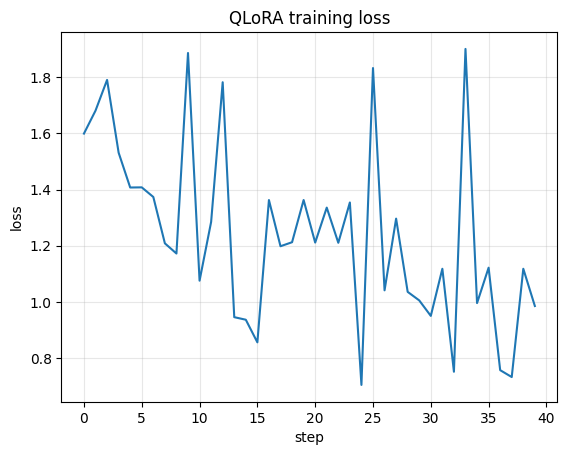

In [31]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

try:
    free_memory(); torch.cuda.reset_peak_memory_stats()
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, device_map="cuda")
    base = prepare_model_for_kbit_training(base)
    qlora = get_peft_model(base, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                                            target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
                                            task_type="CAUSAL_LM"))
    qlora.print_trainable_parameters()

    ds = load_dataset("yahma/alpaca-cleaned", split="train[:256]")
    texts = [tokenizer.apply_chat_template(
                [{"role": "user", "content": (e["instruction"] + "\n" + e["input"]).strip()},
                 {"role": "assistant", "content": e["output"]}], tokenize=False) for e in ds]

    opt = torch.optim.AdamW([p for p in qlora.parameters() if p.requires_grad], lr=2e-4)
    scaler = torch.amp.GradScaler("cuda")
    BS, STEPS, losses = 4, 40, []
    qlora.train()
    for step in range(STEPS):
        batch = [texts[(step * BS + i) % len(texts)] for i in range(BS)]
        enc = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=256).to("cuda")
        labels = enc.input_ids.clone(); labels[enc.attention_mask == 0] = -100
        with torch.autocast("cuda", dtype=torch.float16):
            loss = qlora(**enc, labels=labels).loss
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); opt.zero_grad()
        losses.append(loss.item())
        if step % 10 == 0: print(f"step {step:3d} | loss {loss.item():.3f}")

    print(f"Peak GPU while training: {torch.cuda.max_memory_allocated()/2**30:.2f} GB")
    plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.title("QLoRA training loss"); plt.grid(alpha=.3); plt.show()
    # qlora.save_pretrained("my-qlora-adapter")   # adapter is only a few MB
except Exception as e:
    print(f"⚠️  QLoRA demo failed: {type(e).__name__}: {str(e)[:300]}")
finally:
    for v in ("base", "qlora", "opt"):
        if v in globals(): del globals()[v]
    free_memory()

## 13. QAT — Quantization-Aware Training

PTQ can't recover everything at very low bit-widths. **QAT** inserts *fake quantization* (quantize → dequantize) into the forward pass so the network trains while "seeing" rounding noise. Rounding has zero gradient almost everywhere, so we use the **straight-through estimator (STE)**: forward uses the quantized value, backward pretends rounding was the identity.

Below: a small MLP on `sklearn` digits. We compare **PTQ** (train in FP32, then round) with **QAT** (fine-tune with fake-quant) at 4, 3, and 2 bits. For LLMs, the same idea is applied at scale by TorchAO's QAT API, Llama 3.2 "QLoRA-QAT" releases, and BitNet-style training from scratch.

In [32]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

Xd, yd = load_digits(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xd / 16.0, yd, test_size=0.3, random_state=0)
Xtr, Xte = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(Xte, dtype=torch.float32)
ytr, yte = torch.tensor(ytr), torch.tensor(yte)

def fake_quant_ste(w, bits):
    qmax = 2 ** (bits - 1) - 1
    s = w.abs().amax(dim=1, keepdim=True).clamp(min=1e-8) / qmax
    w_q = torch.round(w / s).clamp(-qmax - 1, qmax) * s
    return w + (w_q - w).detach()               # STE: forward = w_q, backward = identity

class QLinear(nn.Linear):
    bits = None
    def forward(self, x):
        w = self.weight if self.bits is None else fake_quant_ste(self.weight, self.bits)
        return F.linear(x, w, self.bias)

def make_mlp(): return nn.Sequential(QLinear(64, 128), nn.ReLU(), QLinear(128, 128), nn.ReLU(), QLinear(128, 10))
def set_bits(m, b):
    for l in m.modules():
        if isinstance(l, QLinear): l.bits = b
def acc(m):
    with torch.no_grad(): return (m(Xte).argmax(1) == yte).float().mean().item()
def fit(m, epochs, lr=1e-2):
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    for _ in range(epochs):
        opt.zero_grad(); F.cross_entropy(m(Xtr), ytr).backward(); opt.step()

torch.manual_seed(0)
fp = make_mlp(); fit(fp, 300)
print(f"FP32 accuracy: {acc(fp):.3f}")
rows = []
for b in [4, 3, 2]:
    set_bits(fp, b); ptq = acc(fp); set_bits(fp, None)           # PTQ: just round
    qat = make_mlp(); qat.load_state_dict(fp.state_dict()); set_bits(qat, b)
    fit(qat, 200, lr=3e-3); rows.append(dict(bits=b, PTQ_acc=ptq, QAT_acc=acc(qat)))
display(pd.DataFrame(rows).set_index("bits").round(3))

FP32 accuracy: 0.963


,PTQ_acc,QAT_acc
bits,,
4,0.957,0.959
3,0.952,0.959
2,0.220,0.952


## 14. Other methods worth knowing (overview)

These need larger GPUs, special kernels, or very long runtimes, so they are described rather than run.

| Method | Idea | Why it matters |
|---|---|---|
| **AQLM** | *Additive* vector quantization: groups of weights are represented as sums of learned codebook entries | State of the art at ~2 bits/weight; slow to quantize, good decode kernels |
| **QuIP / QuIP#** | Incoherence processing (random Hadamard rotations) + lattice codebooks | Makes 2-bit viable by removing outliers before quantizing |
| **SpQR / SqueezeLLM** | Keep a *sparse* set of outlier weights in high precision, quantize the rest | Near-lossless 3–4 bit |
| **QuaRot / SpinQuant** | Rotate weights and activations to remove activation outliers, enabling W4A4 | Fully 4-bit inference |
| **FP8 (E4M3/E5M2)** | 8-bit float for weights + activations + KV cache | Default for H100/L40/Blackwell serving (vLLM, TensorRT-LLM) |
| **MXFP4 / NVFP4** | Micro-scaling 4-bit floats with shared block exponents | Native on newest GPUs; used by recent open-weights releases |
| **BitNet b1.58** | Ternary weights {−1, 0, +1}, trained from scratch (QAT) | ~1.58 bits/weight; multiplication-free matmuls |
| **Marlin / Machete kernels** | Fast mixed-precision (W4A16) GPU kernels | Make GPTQ/AWQ checkpoints much faster at batch > 1 |
| **EETQ** | Per-channel INT8 weight-only, no calibration | Quick 8-bit option |
| **Mixed-precision / layer-wise** | Give sensitive layers more bits (what K-quants do informally) | Free quality at the same average bits |

### Serving quantized models



In [33]:
!pip uninstall vllm -y

In [34]:
# vLLM: AWQ / GPTQ / FP8 / bitsandbytes are selected with one argument
try:
    from vllm import LLM
    llm = LLM("Qwen/Qwen2.5-1.5B-Instruct-AWQ", quantization="awq")   # or "gptq", "fp8", "bitsandbytes"
    print(llm.generate("Hello!")[0].outputs[0].text)
except ModuleNotFoundError:
    print("⚠️  vLLM is not installed. To run this serving example, install it via: !pip install vllm")

⚠️  vLLM is not installed. To run this serving example, install it via: !pip install vllm


In [35]:
# llama.cpp server for GGUF  (run in a terminal on your own machine, not in Colab)
# !llama-server -m model-q4_k_m.gguf -ngl 99 -c 8192

# Ollama  (also a local tool)
# !ollama run qwen2.5:1.5b-instruct-q4_K_M

## 15. Final comparison

In [36]:
df = pd.DataFrame(RESULTS)
base = df[df.name == "FP16 baseline"].iloc[0]
df["size_vs_fp16"] = (df.size_mb / base.size_mb).round(3)
df["ppl_delta_%"] = ((df.perplexity / base.perplexity - 1) * 100).round(2)
df["speedup_vs_fp16"] = (df.tokens_per_s / base.tokens_per_s).round(2)
cols = ["name", "family", "bits", "size_mb", "size_vs_fp16", "perplexity", "ppl_delta_%",
        "tokens_per_s", "speedup_vs_fp16", "peak_gpu_mb"]
table = df[cols].sort_values("size_mb").reset_index(drop=True)
display(table.style.format(precision=2).background_gradient(subset=["ppl_delta_%"], cmap="RdYlGn_r"))
table.to_csv("quantization_results.csv", index=False)

,name,family,bits,size_mb,size_vs_fp16,perplexity,ppl_delta_%,tokens_per_s,speedup_vs_fp16,peak_gpu_mb
0,GGUF Q2_K,GGUF,3.40,718.00,0.24,20.99,75.91,97.50,16.53,nan
1,GGUF Q3_K_M,GGUF,3.90,881.60,0.30,13.65,14.40,73.40,12.44,nan
2,RTN W3 group-128 (simulated),RTN (simulated),3.00,933.50,0.32,104.00,771.72,nan,nan,nan
3,GGUF Q4_K_M,GGUF,4.80,1065.60,0.36,12.70,6.47,116.00,19.66,nan
4,bnb FP4,bitsandbytes,4.00,1070.20,0.36,14.46,21.15,8.20,1.39,1176.00
5,RTN W4 per-channel (simulated),RTN (simulated),4.00,1070.20,0.36,21.92,83.75,nan,nan,nan
6,bnb NF4 + double quant,bitsandbytes,4.00,1070.20,0.36,13.07,9.51,8.60,1.46,1118.00
7,bnb NF4 (no double quant),bitsandbytes,4.00,1070.20,0.36,13.07,9.53,7.20,1.22,1176.00
8,RTN W4 group-128 (simulated),RTN (simulated),4.00,1089.70,0.37,14.59,22.30,nan,nan,nan
9,AWQ INT4 (pre-quantized),AWQ,4.00,1094.60,0.37,13.04,9.25,16.60,2.81,2306.00


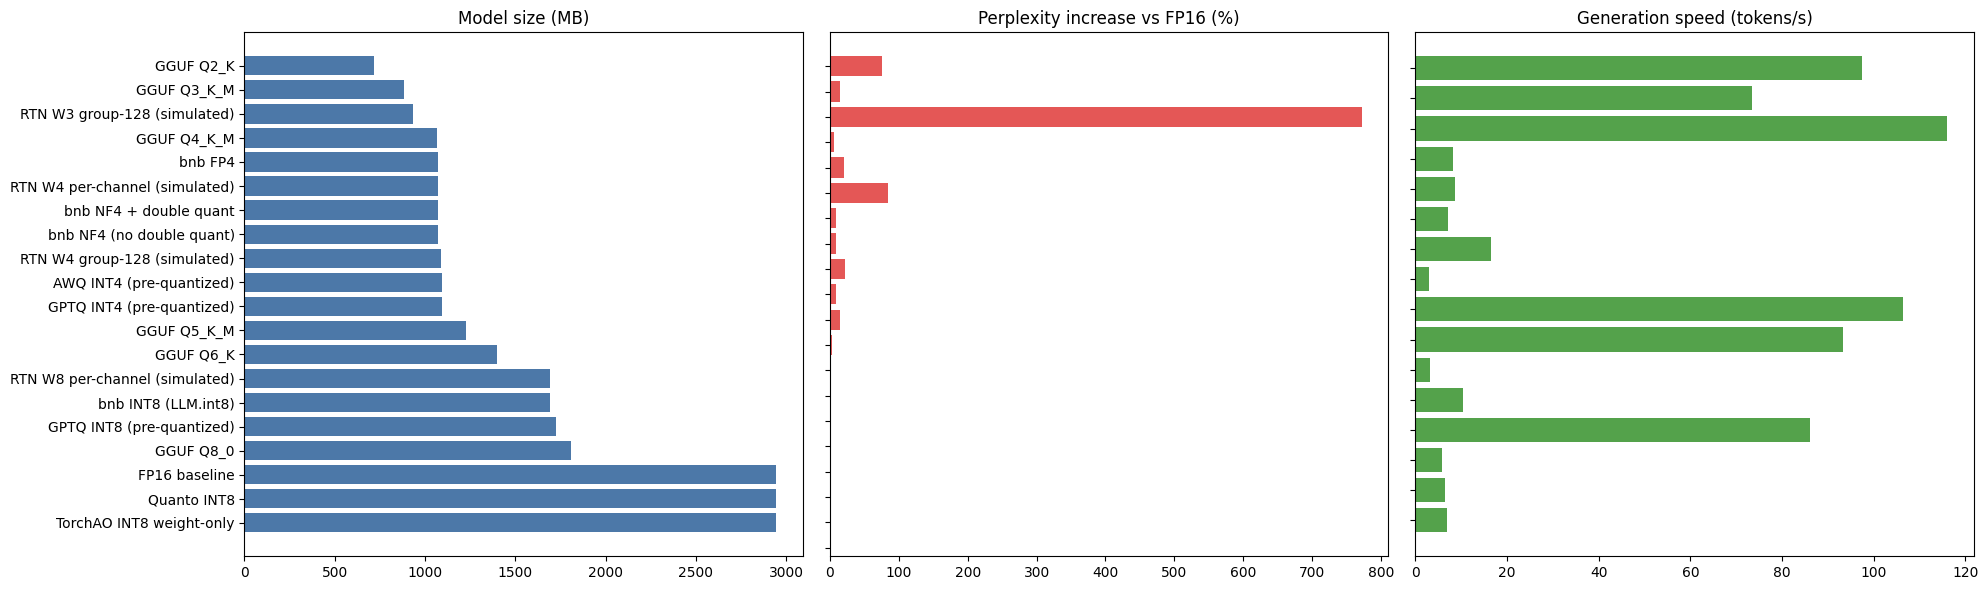

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
t = table.sort_values("size_mb")

ax[0].barh(t.name, t.size_mb, color="#4C78A8"); ax[0].set_title("Model size (MB)"); ax[0].invert_yaxis()
ax[1].barh(t.name, t["ppl_delta_%"], color="#E45756"); ax[1].set_title("Perplexity increase vs FP16 (%)")
ax[1].invert_yaxis(); ax[1].set_yticklabels([])
ts = t.dropna(subset=["tokens_per_s"])
ax[2].barh(ts.name, ts.tokens_per_s, color="#54A24B"); ax[2].set_title("Generation speed (tokens/s)")
ax[2].invert_yaxis(); ax[2].set_yticklabels([])
plt.tight_layout(); plt.show()

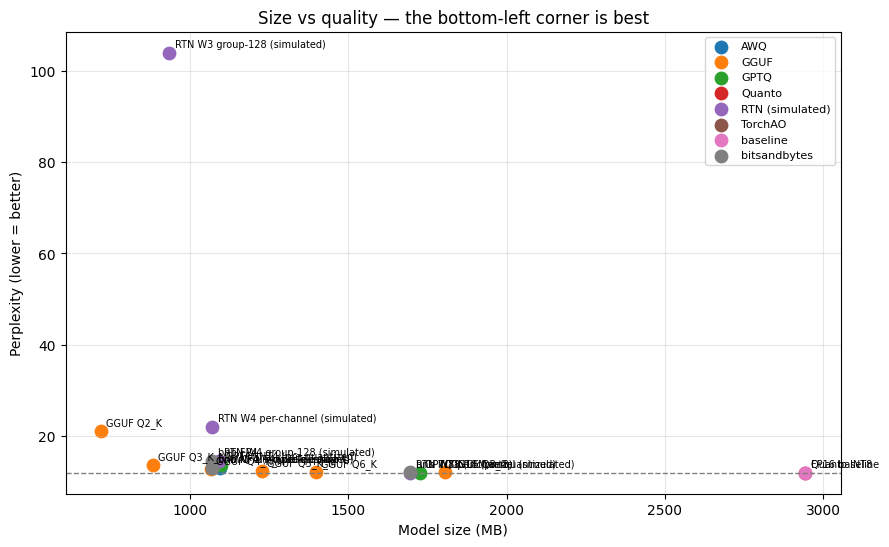

In [38]:
# The classic Pareto view: smaller is better on x, lower perplexity on y
plt.figure(figsize=(10, 6))
for fam, g in table.groupby("family"):
    plt.scatter(g.size_mb, g.perplexity, s=80, label=fam)
    for _, r in g.iterrows():
        plt.annotate(r["name"], (r.size_mb, r.perplexity), fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.axhline(base.perplexity, ls="--", c="gray", lw=1)
plt.xlabel("Model size (MB)"); plt.ylabel("Perplexity (lower = better)")
plt.title("Size vs quality — the bottom-left corner is best"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.show()

In [39]:
# Do they still *sound* the same? One greedy answer per model:
for r in sorted(RESULTS, key=lambda r: r["size_mb"], reverse=True):
    if r.get("sample"):
        print(f"--- {r['name']} ({r['size_mb']:.0f} MB, ppl {r['perplexity']}) ---")
        print(r["sample"][:300].replace("\n", " "), "\n")

--- FP16 baseline (2944 MB, ppl 11.931) ---
Quantization of neural networks involves reducing the precision of weights and activations to lower bit representations (e.g., from 32-bit floating-point to 8-bit integers), which can significantly reduce memory usage and inference time while maintaining or even improving accuracy compared to full-p 

--- Quanto INT8 (2944 MB, ppl 11.976) ---
Quantization of neural networks involves reducing the precision of weights and activations to lower bit representations (e.g., from 32-bit floating-point to 8-bit integers), which can significantly reduce memory usage and inference time while maintaining or even improving accuracy compared to full-p 

--- TorchAO INT8 weight-only (2944 MB, ppl nan) ---
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! 

--- GGUF Q8_0 (1807 MB, ppl 12.086) ---
Quantization of neural networks is the process of reducing the precision of the weigh

## 16. Publish every quantized model to the Hugging Face Hub

So far we only *evaluated* models in memory. In this last section we **quantize, save and upload each method as its own Hub repo**, so anyone can load a single model with one line of code and reproduce the benchmark numbers above.

Each repo gets an auto-generated **model card** (base model, method, usage snippet, and the size / perplexity / speed table measured in this notebook).

| Method | Repo name (pattern) | Load with |
|---|---|---|
| bitsandbytes NF4 | `<user>/<model>-bnb-NF4` | `transformers` |
| bitsandbytes INT8 | `<user>/<model>-bnb-INT8` | `transformers` |
| GPTQ 4-bit, group 128 | `<user>/<model>-GPTQ-W4-g128` | `transformers` + `gptqmodel` |
| AWQ 4-bit, group 128 | `<user>/<model>-AWQ-W4-g128` | `transformers` + `autoawq` |
| HQQ 4-bit, group 64 | `<user>/<model>-HQQ-W4-g64` | `transformers` + `hqq` |
| GGUF (Q2_K to Q8_0 + F16) | `<user>/<model>-GGUF` | `llama.cpp`, Ollama, LM Studio |

**Before you run:**
1. Create a Hugging Face token with **Write** access (Settings, then Access Tokens).
2. In Colab click the key icon (Secrets), add `HF_TOKEN`, and turn on *Notebook access*. Never paste a token into a cell.
3. Expect about 30 to 45 minutes in total (GPTQ and AWQ are the slow ones) and a few GB of uploads. Local folders are deleted after each upload to save Colab disk.
4. Quanto and TorchAO are not published here: their save formats are still changing between releases. The six methods above load with a standard `from_pretrained` (or llama.cpp for GGUF).
5. Set `PRIVATE = True` in the first cell if you want to review the repos before making them public.

In [40]:
!pip install -q huggingface_hub
import shutil
from huggingface_hub import HfApi, login, create_repo, upload_folder

try:
    from google.colab import userdata
    login(token=userdata.get("HF_TOKEN"))      # Colab Secrets: key icon -> HF_ACCESS_TOKEN (write access)
except Exception:
    login()                                    # fallback: paste a WRITE token when asked

api = HfApi()
HF_USERNAME = api.whoami()["name"]
PRIVATE = False                                # True = review first, make public later
LICENSE = "apache-2.0"                         # must match the base model (Qwen2.5-3B / 72B use other licenses!)
SHORT = MODEL_ID.split("/")[-1]                # e.g. Qwen2.5-1.5B-Instruct

REPOS = {
    "nf4":  f"{HF_USERNAME}/{SHORT}-bnb-NF4",
    "int8": f"{HF_USERNAME}/{SHORT}-bnb-INT8",
    "gptq": f"{HF_USERNAME}/{SHORT}-GPTQ-W4-g128",
    "awq":  f"{HF_USERNAME}/{SHORT}-AWQ-W4-g128",
    "hqq":  f"{HF_USERNAME}/{SHORT}-HQQ-W4-g64",
    "gguf": f"{HF_USERNAME}/{SHORT}-GGUF",
}
PUBLISHED = []
os.makedirs("out", exist_ok=True)
print("Logged in as:", HF_USERNAME)
for k, v in REPOS.items():
    print(f"  {k:5s} -> {v}")

Logged in as: Youssefx64
  nf4   -> Youssefx64/Qwen2.5-1.5B-Instruct-bnb-NF4
  int8  -> Youssefx64/Qwen2.5-1.5B-Instruct-bnb-INT8
  gptq  -> Youssefx64/Qwen2.5-1.5B-Instruct-GPTQ-W4-g128
  awq   -> Youssefx64/Qwen2.5-1.5B-Instruct-AWQ-W4-g128
  hqq   -> Youssefx64/Qwen2.5-1.5B-Instruct-HQQ-W4-g64
  gguf  -> Youssefx64/Qwen2.5-1.5B-Instruct-GGUF


In [1]:
def get_result(name):
    return next((r for r in RESULTS if r["name"] == name), None)

def make_card(repo_id, title, tags, bits, result_name=None, requires="", library="transformers", usage=None):
    base = get_result("FP16 baseline")
    r = get_result(result_name) if result_name else None

    bench = ""
    if base and r:
        bench = f"""
## Benchmark vs the original FP16 model

| | FP16 (original) | This model |
|---|---|---|
| Size (MB) | {base['size_mb']} | **{r['size_mb']}** ({r['size_mb'] / base['size_mb']:.2f}x) |
| Perplexity, Wikitext-2 (lower is better) | {base['perplexity']} | **{r['perplexity']}** ({(r['perplexity'] / base['perplexity'] - 1) * 100:+.1f}%) |
| Generation speed (tokens/s, T4, batch 1) | {base['tokens_per_s']} | **{r['tokens_per_s']}** |

Measured on a free Colab T4 using {PPL_CHUNKS} windows of {PPL_CTX} tokens. Perplexity is only a proxy for quality, so please test on your own task.
"""

    usage = usage or f'''~~~python
from transformers import AutoModelForCausalLM, AutoTokenizer

tok = AutoTokenizer.from_pretrained("{repo_id}")
model = AutoModelForCausalLM.from_pretrained("{repo_id}", device_map="auto")

msgs = [{{"role": "user", "content": "Explain quantization in one paragraph."}}]
text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
inputs = tok(text, return_tensors="pt").to(model.device)
out = model.generate(**inputs, max_new_tokens=200)
print(tok.decode(out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True))
~~~'''

    return f"""---
base_model: {MODEL_ID}
library_name: {library}
license: {LICENSE}
pipeline_tag: text-generation
language:
- en
tags:
- quantization
- {bits}-bit
{chr(10).join('- ' + t.strip() for t in tags.split(','))}
---

# {SHORT} - {title}

{bits}-bit **{title}** quantization of [{MODEL_ID}](https://huggingface.co/{MODEL_ID}), produced with the open notebook *LLM Quantization: A Practical, Hands-On Reference*.
{bench}
## Usage

{requires}
{usage}

## Notes

- Quantized post-training from the original weights. No fine-tuning was done.
- The license and usage terms of the base model apply.
"""

def push_dir(local_dir, repo_id, card):
    create_repo(repo_id, private=PRIVATE, exist_ok=True)
    with open(f"{local_dir}/README.md", "w") as f:
        f.write(card)
    upload_folder(folder_path=local_dir, repo_id=repo_id, commit_message="Upload quantized model")
    PUBLISHED.append(repo_id)
    print("✅ https://huggingface.co/" + repo_id)
    shutil.rmtree(local_dir, ignore_errors=True)

In [42]:
bnb_jobs = [
    ("nf4",
     BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                        bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16),
     "bitsandbytes NF4 (double quant)", "bitsandbytes, nf4", 4, "bnb NF4 + double quant"),
    ("int8",
     BitsAndBytesConfig(load_in_8bit=True),
     "bitsandbytes INT8 (LLM.int8)", "bitsandbytes, int8, llm-int8", 8, "bnb INT8 (LLM.int8)"),
]

for key, cfg, title, tags, bits, rname in bnb_jobs:
    try:
        free_memory()
        m = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=cfg, device_map="cuda", torch_dtype=torch.float16)
        d = f"out/{key}"
        m.save_pretrained(d); tokenizer.save_pretrained(d)
        del m; free_memory()
        card = make_card(REPOS[key], title, tags, bits, rname,
                         requires="Requires `pip install -U bitsandbytes accelerate transformers` and an NVIDIA GPU.\n")
        push_dir(d, REPOS[key], card)
    except Exception as e:
        print(f"⚠️  {key} failed: {type(e).__name__}: {str(e)[:300]}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ https://huggingface.co/Youssefx64/Qwen2.5-1.5B-Instruct-bnb-NF4


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ https://huggingface.co/Youssefx64/Qwen2.5-1.5B-Instruct-bnb-INT8


In [43]:
from gptqmodel import GPTQModel, GPTQConfig as GPTQMConfig
from transformers import GPTQConfig

key, rname = "gptq", "GPTQ INT4 (own, wikitext calib)"
d = f"out/{key}"
try:
    free_memory()
    if os.path.isdir("my-gptq-4bit"):                      # reuse the model from section 5 if you made it
        shutil.copytree("my-gptq-4bit", d, dirs_exist_ok=True)
    else:
        train = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
        calib = [t for t in train["text"] if len(t) > 500][:128]      # train split, never the test set
        m = GPTQModel.load(MODEL_ID, GPTQMConfig(bits=4, group_size=128))
        m.quantize(calib, batch_size=1)
        m.save(d); tokenizer.save_pretrained(d)
        del m; free_memory()

    for backend in ("gptq_triton", "gptq_torch"):                  # Marlin's JIT build fails on Colab's T4
        if run(rname, "GPTQ", 4, model_id=d, torch_dtype=torch.float16,
               quantization_config=GPTQConfig(bits=4, backend=backend)):   # benchmark, fills the model card
            break
    card = make_card(REPOS[key], "GPTQ W4 g128", "gptq, auto-gptq", 4, rname,
                     requires="Requires `pip install -U transformers optimum gptqmodel accelerate` and an NVIDIA GPU.\n")
    push_dir(d, REPOS[key], card)
except Exception as e:
    print(f"⚠️  {key} failed: {type(e).__name__}: {str(e)[:300]}")

INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_6jort343`


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

INFO  Loader: Auto dtype (native bfloat16): `torch.bfloat16`                    
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  Loader: using checkpoint-backed lazy turtle source for `/root/.cache/huggingface/hub/models--Qwen--Qwen2.5-1.5B-Instruct/snapshots/989aa7980e4cf806f80c7fef2b1adb7bc71aa306`
INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "pad_token_id": 151643,
  "use_cache": true
}

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.1,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}

INFO  Kernel: loaded -> `[]`                         

In [44]:
from gptqmodel import GPTQModel, AWQConfig

key, rname = "awq", "AWQ INT4 (own)"
d = f"out/{key}"
try:
    free_memory()
    if os.path.isdir("my-awq-4bit"):                       # reuse the model from section 6 if you made it
        shutil.copytree("my-awq-4bit", d, dirs_exist_ok=True)
    else:
        # AutoAWQ (`import awq`) no longer imports with current torch / transformers; GPTQModel runs the same AWQ algorithm.
        train = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
        calib = [t for t in train["text"] if len(t) > 500][:128]
        m = GPTQModel.load(MODEL_ID, AWQConfig(bits=4, group_size=128))
        m.quantize(calib, batch_size=1)
        m.save(d); tokenizer.save_pretrained(d)
        del m; free_memory()

    run(rname, "AWQ", 4, model_id=d, torch_dtype=torch.float16)
    card = make_card(REPOS[key], "AWQ W4 g128", "awq", 4, rname,
                     requires="Requires `pip install -U transformers gptqmodel accelerate` and an NVIDIA GPU.\n")
    push_dir(d, REPOS[key], card)
except Exception as e:
    print(f"⚠️  {key} failed: {type(e).__name__}: {str(e)[:300]}")

INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_fuq1bjtz`


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

INFO  Loader: Auto dtype (native bfloat16): `torch.bfloat16`                    
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  Loader: using checkpoint-backed lazy turtle source for `/root/.cache/huggingface/hub/models--Qwen--Qwen2.5-1.5B-Instruct/snapshots/989aa7980e4cf806f80c7fef2b1adb7bc71aa306`
INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "pad_token_id": 151643,
  "use_cache": true
}

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.1,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}

INFO  Kernel: loaded -> `[]`                         

In [45]:
from transformers import HqqConfig

key, rname = "hqq", "HQQ INT4 g64"
d = f"out/{key}"
try:
    import importlib, transformers.quantizers.quantizer_hqq as _qh
    importlib.reload(_qh)             # picks up HQQLinear if hqq was installed after transformers was imported
    free_memory()
    m = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="cuda",
                                             quantization_config=HqqConfig(nbits=4, group_size=64))
    try:
        m.save_pretrained(d)
    except Exception:
        m.save_pretrained(d, safe_serialization=False)      # fallback for older HQQ / transformers combos
    tokenizer.save_pretrained(d)
    del m; free_memory()

    card = make_card(REPOS[key], "HQQ W4 g64", "hqq", 4, rname,
                     requires="Requires `pip install -U transformers hqq accelerate` and an NVIDIA GPU.\n")
    push_dir(d, REPOS[key], card)
except Exception as e:
    print(f"⚠️  {key} failed: {type(e).__name__}: {str(e)[:300]}")

⚠️  hqq failed: NotImplementedError: QuantizationMethod.HQQ is not available yet and will be supported soon.


In [ ]:
from huggingface_hub import snapshot_download
import os

# Ensure dependent configuration variables exist locally if previous cells weren't run
if "MODEL_ID" not in globals():
    MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
if "SHORT" not in globals():
    SHORT = MODEL_ID.split("/")[-1]
if "HF_USERNAME" not in globals():
    from huggingface_hub import HfApi
    try:
        HF_USERNAME = HfApi().whoami()["name"]
    except Exception:
        HF_USERNAME = "anonymous"
if "REPOS" not in globals():
    REPOS = {"gguf": f"{HF_USERNAME}/{SHORT}-GGUF"}

_need = [n for n in ("make_card", "push_dir", "PUBLISHED") if n not in globals()]
if _need:
    raise RuntimeError(f"Run the section-16 login cell and the helper cell first (missing: {_need}). "
                       "After a runtime restart, also re-run the setup cells at the top.")

QUANTS = ["Q2_K", "Q3_K_M", "Q4_K_M", "Q5_K_M", "Q6_K", "Q8_0"]
key, stem = "gguf", SHORT.lower()
d = f"out/{key}"
try:
    if not os.path.isdir("llama.cpp"):
        !git clone -q --depth 1 https://github.com/ggml-org/llama.cpp
        !pip install -q -r llama.cpp/requirements/requirements-convert_hf_to_gguf.txt
    if not os.path.exists("llama.cpp/build/bin/llama-quantize"):
        !cmake -S llama.cpp -B llama.cpp/build -DGGML_CUDA=OFF -DLLAMA_CURL=OFF > /dev/null
        !cmake --build llama.cpp/build --config Release -j --target llama-quantize > /dev/null

    snapshot_download(MODEL_ID, local_dir="hf_model")
    os.makedirs(d, exist_ok=True)
    f16 = f"{d}/{stem}-f16.gguf"
    !python llama.cpp/convert_hf_to_gguf.py hf_model --outfile {f16} --outtype f16
    for q in QUANTS:
        ql = q.lower()
        !llama.cpp/build/bin/llama-quantize {f16} {d}/{stem}-{ql}.gguf {q}

    rows = "\n".join(f"| `{f}` | {os.path.getsize(f'{d}/{f}') / 2**20:.0f} MB |"
                     for f in sorted(os.listdir(d), key=lambda f: os.path.getsize(f"{d}/{f}")))
    repo = REPOS[key]
    usage = f"""### Files

| File | Size |
|---|---|
{rows}

`Q4_K_M` is the best default. Use `Q5_K_M` or `Q6_K` if you have spare memory, and `Q2_K` / `Q3_K_M` only when memory is very tight.

### Run

~~~bash
llama-cli -hf {repo}:Q4_K_M -p "Explain quantization in one paragraph."
ollama run hf.co/{repo}:Q4_K_M
~~~"""
    card = make_card(repo, "GGUF (Q2_K to Q8_0)", "gguf, llama-cpp, k-quants", "2-8", usage=usage, library="gguf")
    push_dir(d, repo, card)
except Exception as e:
    print(f"⚠️  {key} failed: {type(e).__name__}: {str(e)[:300]}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 110.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.5/118.5 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 104.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
gptqmodel 7.5.0 requires protobuf>=7.34.0, but you have protobuf 4.25.9 which is incompatible.
gptqmodel 7.5.0 requires transformers>=5.14.0, but you have transformers 4.57.6 which is incompatible.
google-cloud-dataproc 5.30.0 requ

In [2]:
from huggingface_hub import HfApi

if "api" not in globals():
    api = HfApi()
if "MODEL_ID" not in globals():
    MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
if "SHORT" not in globals():
    SHORT = MODEL_ID.split("/")[-1]
if "HF_USERNAME" not in globals():
    HF_USERNAME = api.whoami()["name"]
if "REPOS" not in globals() or len(REPOS) < 6:
    REPOS = {
        "nf4":  f"{HF_USERNAME}/{SHORT}-bnb-NF4",
        "int8": f"{HF_USERNAME}/{SHORT}-bnb-INT8",
        "gptq": f"{HF_USERNAME}/{SHORT}-GPTQ-W4-g128",
        "awq":  f"{HF_USERNAME}/{SHORT}-AWQ-W4-g128",
        "hqq":  f"{HF_USERNAME}/{SHORT}-HQQ-W4-g64",
        "gguf": f"{HF_USERNAME}/{SHORT}-GGUF",
    }

# Ensure PUBLISHED variable exists. After a runtime restart it is empty, so rebuild it from the repos that exist on the Hub.
if "PUBLISHED" not in globals():
    PUBLISHED = []
if not PUBLISHED:
    PUBLISHED = [r for r in REPOS.values() if api.repo_exists(r)]

print("Published repos:")
for r in PUBLISHED:
    print("  https://huggingface.co/" + r)

try:
    slug = api.create_collection(
        title=f"{SHORT} - quantization zoo",
        namespace=HF_USERNAME,
        description="One base model quantized with bitsandbytes, GPTQ, AWQ, HQQ and GGUF, with size / perplexity / speed benchmarks.",
        exists_ok=True,
    ).slug
    for r in PUBLISHED:
        api.add_collection_item(slug, item_id=r, item_type="model", exists_ok=True)
    print("\nCollection (link this one on your portfolio):\nhttps://huggingface.co/collections/" + slug)
except Exception as e:
    print(f"⚠️  Collection step skipped: {type(e).__name__}: {str(e)[:300]}")

print("\nMarkdown list for your website / GitHub README:")
for r in PUBLISHED:
    print(f"- [{r.split('/')[-1]}](https://huggingface.co/{r})")

Published repos:
  https://huggingface.co/Youssefx64/Qwen2.5-1.5B-Instruct-bnb-NF4
  https://huggingface.co/Youssefx64/Qwen2.5-1.5B-Instruct-bnb-INT8
⚠️  Collection step skipped: HfHubHTTPError: (Request ID: Root=1-6acb651b-005b4cc65b383cbb66b6aeaa;84fde047-1d58-4b21-bb88-279fa68381a0)

403 Forbidden: You don't have the required permissions to complete this action.
Cannot access content at: https://huggingface.co/api/collections.
Make sure your token has the correct permissions.

Markdown list for your website / GitHub README:
- [Qwen2.5-1.5B-Instruct-bnb-NF4](https://huggingface.co/Youssefx64/Qwen2.5-1.5B-Instruct-bnb-NF4)
- [Qwen2.5-1.5B-Instruct-bnb-INT8](https://huggingface.co/Youssefx64/Qwen2.5-1.5B-Instruct-bnb-INT8)


## Decision guide

| Your situation | Start with | Why |
|---|---|---|
| Laptop / CPU / Apple Silicon / Ollama | **GGUF Q4_K_M** (Q5_K_M if you have room) | Best CPU/Metal support; one file |
| NVIDIA GPU, single-user or low batch, max speed | **AWQ 4-bit** or **GPTQ 4-bit** (+ Marlin kernels) | Mature fast W4A16 kernels |
| High-throughput serving on H100/L40 | **FP8** or **W8A8 (SmoothQuant)** | Uses low-precision tensor cores for the math, not just storage |
| Just need it to fit, no time to calibrate | **bitsandbytes NF4 / INT8** or **HQQ** | One line of code |
| Fine-tuning on a small GPU | **QLoRA (NF4)** | Train adapters on a frozen 4-bit base |
| Going below 4 bit | **HQQ**, **AQLM**, **QuIP#**, GGUF I-quants (+imatrix) | Designed for extreme compression; consider QAT |
| Need near-lossless | **INT8 (bnb / GPTQ-Int8 / Q8_0)** or **Q6_K** | <1% perplexity change typically |

### Rules of thumb

1. **4-bit is the sweet spot:** ~3.5–4× smaller than FP16 with a small quality loss, especially with group-wise scales.
2. **Bigger model at lower bits usually beats a smaller model at higher bits** (e.g., 7B @ 4-bit > 3B @ 8-bit), until you reach ~2–3 bits.
3. **Small models hurt more:** quantizing a 1B model degrades quality more than quantizing a 70B one.
4. **Calibration data should look like your use case** (code model → code calibration).
5. **Memory saving ≠ speed-up.** bitsandbytes saves memory but can be slower than FP16; speed depends on the kernel.
6. **Always evaluate on your task**, not only perplexity (MMLU, GSM8K, HumanEval, or your own prompts). `lm-evaluation-harness` makes this a one-liner.

## Further reading

* Dettmers et al. — *LLM.int8(): 8-bit Matrix Multiplication for Transformers at Scale* (2022)
* Frantar et al. — *GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers* (2022)
* Xiao et al. — *SmoothQuant: Accurate and Efficient Post-Training Quantization for LLMs* (2022)
* Dettmers et al. — *QLoRA: Efficient Finetuning of Quantized LLMs* (2023)
* Lin et al. — *AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration* (2023)
* Badri & Shaji — *Half-Quadratic Quantization of Large Machine Learning Models* (2023)
* Egiazarian et al. — *AQLM: Extreme Compression of LLMs via Additive Quantization* (2024)
* Tseng et al. — *QuIP#: Even Better LLM Quantization with Hadamard Incoherence and Lattice Codebooks* (2024)
* Ma et al. — *The Era of 1-bit LLMs: BitNet b1.58* (2024)
* Hugging Face docs: *Transformers → Quantization*; the `llama.cpp` quantization README; Maarten Grootendorst's *A Visual Guide to Quantization*

---
*Found a bug or want another method added? Open an issue or PR. Share freely, and cite the original papers.*

In [3]:
# Optional cleanup & export: HTML version for publishing on a website
# (run in a terminal / Colab cell after saving the notebook to Drive or downloading it)
# !jupyter nbconvert --to html LLM_Quantization_Guide.ipynb
print("Done. Results table saved to quantization_results.csv")

Done. Results table saved to quantization_results.csv
